# 3. Hipóteses — Thermal Predictor

Este notebook desenvolve as hipóteses exigidas pela Seção 4.2.3 da documentação (ver [`documents/documentacao.md`](../documents/documentacao.md)), a partir dos padrões levantados na exploração ([`01_exploracao_dados.ipynb`](01_exploracao_dados.ipynb)) e do tratamento definido no pré-processamento ([`02_pre_processamento.ipynb`](02_pre_processamento.ipynb)).

### Recorte adotado

Em vez de formular hipóteses sobre a base inteira, o recorte é feito em **dois sensores (`tc_name`) específicos**:

| Sensor | `key_area` | `active_limit` | Leituras |
|---|---|---|---|
| `Ambient Below Terminal Block` | `Mainback` | 60 °C | 56 |
| `AC Blower Windings` | `Main Vent Sys` | 175 °C | 56 |

A escolha tem uma vantagem metodológica direta: cada sensor tem **exatamente uma leitura por run** (56 runs, 56 leituras), o que elimina a pseudo-replicação que existiria ao agregar todos os 77 termopares por run. A unidade de análise passa a ser o *run*, e cada run entra com peso 1 nos testes estatísticos.

Além disso, ao fixar o sensor, o `active_limit` fica constante dentro de cada recorte (60 °C e 175 °C) — a comparação entre configurações de projeto passa a ser feita contra um mesmo critério de engenharia, sem o efeito de confundimento que aparece quando sensores de limites diferentes são misturados na mesma métrica de excedência.

### Os dois sensores são tratados como fenômenos independentes

O notebook está dividido em dois blocos que **não compartilham hipóteses**. Cada sensor mede um fenômeno físico distinto — temperatura ambiente de um compartimento elétrico (Bloco A) e temperatura de enrolamento de um motor (Bloco B) — e, como os resultados abaixo mostram, respondem a lógicas opostas. Os dois só aparecem lado a lado na hipótese **B3**, que é um achado de qualidade de dados sobre a rotulagem dos *runs*: nesse caso a corroboração cruzada é justamente o que sustenta o argumento, porque o problema está no rótulo do run, não no sensor.

### Hipóteses desenvolvidas

| # | Bloco | Hipótese |
|---|---|---|
| **A1** | `Ambient Below Terminal Block` | A direção do blower é o principal driver térmico do terminal block |
| **A2** | `Ambient Below Terminal Block` | O efeito da direção do blower depende do housing estar aberto (interação) |
| **B1** | `AC Blower Windings` | O enrolamento opera em patamar saturado, sem alavanca de projeto materialmente relevante |
| **B3** | `AC Blower Windings` | Há erro de rotulagem em `run_case` nas Runs 62 e 63 |

## 0. Setup e recorte dos dois sensores

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

df = pd.read_csv('../data/dataset_long.csv')

# Mesma normalizacao minima aplicada no notebook 01: varias categoricas tem a
# mesma categoria grafada de formas diferentes ("To back" vs. "To Back").
CATEGORICAS = ['blower_direction', 'housing', 'deflector_hole', 'run_case',
               'material_coil_support', 'board_position', 'losses']
for col in CATEGORICAS:
    df[col] = df[col].astype('string').str.strip()
df['blower_direction'] = df['blower_direction'].str.title()

df['temp'] = pd.to_numeric(df['temp'])

SENSOR_A, LIMITE_A = 'Ambient Below Terminal Block', 60.0
SENSOR_B, LIMITE_B = 'AC Blower Windings', 175.0

a = df[df['tc_name'] == SENSOR_A].copy()
b = df[df['tc_name'] == SENSOR_B].copy()

sns.set_theme(style='whitegrid')
FIG_DIR = '../assets/graficos'
os.makedirs(FIG_DIR, exist_ok=True)

for nome, rec in [(SENSOR_A, a), (SENSOR_B, b)]:
    print(f'{nome}: {len(rec)} leituras | {rec["run_id"].nunique()} runs unicos | '
          f'key_area={rec["key_area"].unique()[0]} | '
          f'active_limit={rec["active_limit"].unique().tolist()}')

Ambient Below Terminal Block: 56 leituras | 56 runs unicos | key_area=Mainback | active_limit=['60']
AC Blower Windings: 56 leituras | 56 runs unicos | key_area=Main Vent Sys | active_limit=['175']


In [2]:
def perfil(serie, limite, nome):
    """Perfil descritivo de um sensor, incluindo a posicao relativa ao seu limite."""
    excede = serie > limite
    return {
        'sensor': nome,
        'n (runs)': len(serie),
        'media (C)': round(serie.mean(), 2),
        'desvio-padrao (C)': round(serie.std(), 2),
        'CV (%)': round(serie.std() / serie.mean() * 100, 2),
        'min (C)': round(serie.min(), 2),
        'max (C)': round(serie.max(), 2),
        'amplitude (C)': round(serie.max() - serie.min(), 2),
        'active_limit (C)': limite,
        'excedencias': int(excede.sum()),
        'excedencia (%)': round(excede.mean() * 100, 1),
        # Negativa = o pior run ja ultrapassou o limite de engenharia.
        'margem no pior run (C)': round(limite - serie.max(), 2),
    }


perfil_df = pd.DataFrame([
    perfil(a['temp'], LIMITE_A, SENSOR_A),
    perfil(b['temp'], LIMITE_B, SENSOR_B),
]).set_index('sensor').T

perfil_df

sensor,Ambient Below Terminal Block,AC Blower Windings
n (runs),56.00,56.00
media (C),48.83,105.35
desvio-padrao (C),11.79,9.04
CV (%),24.14,8.58
min (C),37.31,92.84
max (C),80.53,135.00
amplitude (C),43.22,42.16
active_limit (C),60.00,175.00
excedencias,9.00,0.00
excedencia (%),16.10,0.00


A tabela já antecipa por que os dois blocos precisam de hipóteses de naturezas diferentes:

- **`Ambient Below Terminal Block`** é um sensor **volátil e em risco**: CV de ~24%, amplitude de 43 °C e **9 excedências em 56 runs (16,1%)**. Opera a poucos graus do seu limite, então faz sentido perguntar *o que causa o estouro*.
- **`AC Blower Windings`** é um sensor **estável e sem risco**: **zero excedências**, com folga de 40 °C em relação ao limite mesmo no pior run registrado. Perguntar "o que causa o estouro" aqui não faz sentido — não há estouro. A pergunta útil vira *o que esse sensor responde, e se ele é sequer informativo para decisões de projeto*.

---

# Bloco A — `Ambient Below Terminal Block`

**Área-chave:** `Mainback` · **Limite de engenharia:** 60 °C · **56 runs**

Sensor de temperatura ambiente logo abaixo do bloco de terminais — um compartimento elétrico. O limite de 60 °C é o mais baixo de toda a base (os demais vão até 220 °C), o que é coerente com a proteção de isolamento de fiação e conexões elétricas, e explica por que este é um dos pontos que mais estoura o limite no dataset inteiro.

## A1 — A direção do blower é o principal driver térmico do terminal block

> **Hipótese:** direcionar o fluxo do soprador para trás (`blower_direction = To Back`) eleva significativamente a temperatura ambiente abaixo do terminal block, sendo o fator isolado de maior impacto sobre esse ponto.

**Justificativa da formulação.** O terminal block fica na região traseira do produto (`key_area = Mainback`). Se o soprador empurra o ar quente do compartimento de aquecimento na direção `To Back`, esse ar é conduzido justamente para a região onde o sensor está, em vez de ser expelido pela frente. A hipótese, portanto, não é uma pescaria estatística: ela tem um mecanismo físico esperado *antes* de olhar os números, e o teste abaixo serve para confirmá-lo ou refutá-lo.

**Como será testada.** Comparação das duas direções por (i) teste *t* de Welch — que não assume variâncias iguais, necessário porque os grupos têm dispersões visivelmente diferentes; (ii) Mann-Whitney, como checagem não-paramétrica dado o *n* pequeno; (iii) tamanho de efeito por *d* de Cohen; e (iv) teste exato de Fisher sobre a taxa de excedência do limite de 60 °C, que é a métrica que interessa ao negócio.

In [3]:
front = a.loc[a['blower_direction'] == 'To Front', 'temp']
back = a.loc[a['blower_direction'] == 'To Back', 'temp']

# (i) Welch: nao assume variancias iguais (sd 15,2 vs. 5,1 -> Student seria inadequado)
t_stat, p_welch = stats.ttest_ind(back, front, equal_var=False)
# (ii) Mann-Whitney: checagem nao-parametrica, robusta ao n pequeno
u_stat, p_mw = stats.mannwhitneyu(back, front, alternative='two-sided')
# (iii) d de Cohen com desvio-padrao agrupado
sp = np.sqrt(((len(back) - 1) * back.var(ddof=1) + (len(front) - 1) * front.var(ddof=1))
             / (len(back) + len(front) - 2))
d_cohen = (back.mean() - front.mean()) / sp

print(f'{"":<12}{"n":>4}{"media":>10}{"sd":>8}{"min":>8}{"max":>8}')
for nome, grupo in [('To Front', front), ('To Back', back)]:
    print(f'{nome:<12}{len(grupo):>4}{grupo.mean():>10.2f}{grupo.std():>8.2f}'
          f'{grupo.min():>8.2f}{grupo.max():>8.2f}')

print(f'\ndiferenca de medias : {back.mean() - front.mean():+.2f} C')
print(f'Welch t             : t={t_stat:.3f}, p={p_welch:.2e}')
print(f'Mann-Whitney        : U={u_stat:.1f}, p={p_mw:.2e}')
print(f'd de Cohen          : {d_cohen:.2f}  (>0,8 ja e considerado efeito grande)')

               n     media      sd     min     max
To Front      39     44.03    5.13   37.31   66.01
To Back       17     59.85   15.18   40.96   80.53

diferenca de medias : +15.81 C
Welch t             : t=4.193, p=5.70e-04
Mann-Whitney        : U=562.5, p=4.00e-05
d de Cohen          : 1.70  (>0,8 ja e considerado efeito grande)


In [4]:
# (iv) Traducao para a metrica de negocio: taxa de excedencia do limite de 60 C.
# Fisher exato em vez de qui-quadrado porque uma das celulas tem contagem 1.
exc_back, n_back = int((back > LIMITE_A).sum()), len(back)
exc_front, n_front = int((front > LIMITE_A).sum()), len(front)

tabela_2x2 = [[exc_back, n_back - exc_back],
              [exc_front, n_front - exc_front]]
odds_ratio, p_fisher = stats.fisher_exact(tabela_2x2)

excedencia = pd.DataFrame({
    'runs': [n_back, n_front],
    'excedem 60 C': [exc_back, exc_front],
    'taxa (%)': [round(exc_back / n_back * 100, 1), round(exc_front / n_front * 100, 1)],
}, index=['To Back', 'To Front'])
excedencia.index.name = 'blower_direction'

print(excedencia.to_string())
print(f'\nFisher exato: odds ratio={odds_ratio:.1f}, p={p_fisher:.2e}')
print(f'Razao entre as taxas: {(exc_back / n_back) / (exc_front / n_front):.1f}x')


def eta2(frame, fator, alvo='temp'):
    """Proporcao da variancia de `alvo` explicada por `fator` (eta ao quadrado)."""
    sub = frame[[fator, alvo]].dropna()
    y = sub[alvo]
    total = ((y - y.mean()) ** 2).sum()
    if total == 0 or sub[fator].nunique() < 2:
        return np.nan
    entre = sum(len(g) * (g.mean() - y.mean()) ** 2 for _, g in sub.groupby(fator, observed=True)[alvo])
    return entre / total


FATORES = ['blower_direction', 'housing', 'deflector_hole', 'run_case',
           'losses', 'material_coil_support', 'board_position']
eta2_a = (pd.Series({f: eta2(a, f) for f in FATORES}, name='eta2')
          .sort_values(ascending=False).round(3))

print('\nVariancia de temp explicada por cada fator (Ambient Below Terminal Block):')
print(eta2_a.to_string())

                  runs  excedem 60 C  taxa (%)
blower_direction                              
To Back             17             8      47.1
To Front            39             1       2.6

Fisher exato: odds ratio=33.8, p=1.28e-04
Razao entre as taxas: 18.4x

Variancia de temp explicada por cada fator (Ambient Below Terminal Block):
blower_direction         0.387
housing                  0.245
deflector_hole           0.241
run_case                 0.236
losses                   0.230
material_coil_support    0.043
board_position           0.022


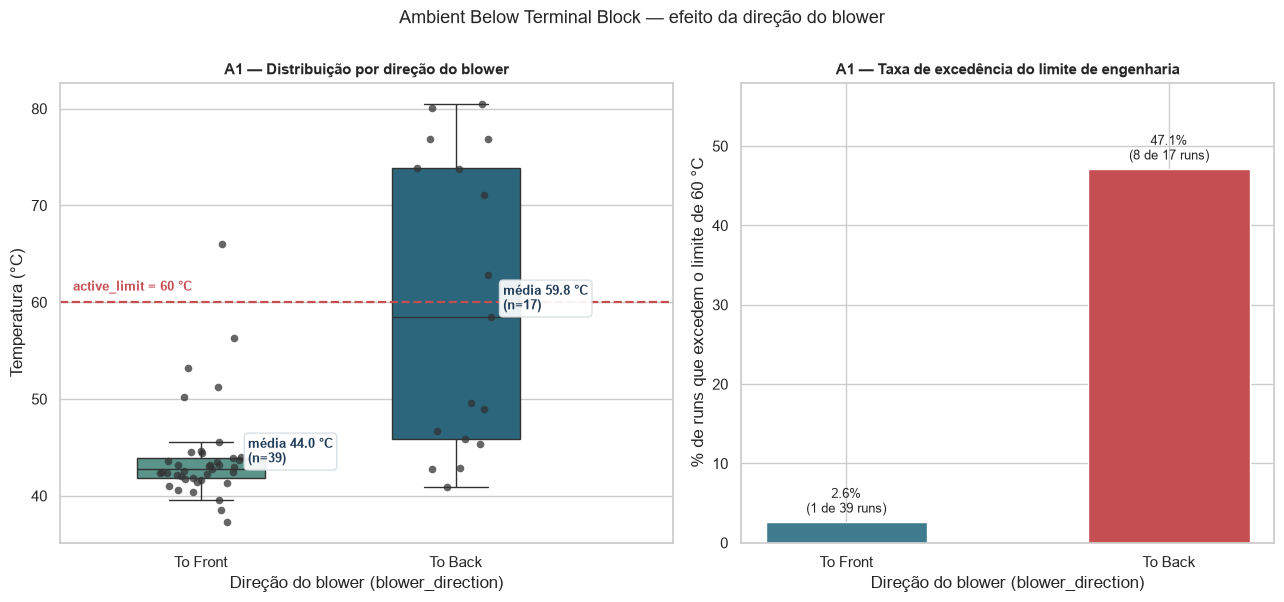

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6), gridspec_kw={'width_ratios': [1.15, 1]})
ordem = ['To Front', 'To Back']

# Painel esquerdo: distribuicao completa (boxplot + pontos individuais dos 56 runs)
ax = axes[0]
sns.boxplot(data=a, x='blower_direction', y='temp', order=ordem, hue='blower_direction',
            hue_order=ordem, palette='crest', legend=False, width=0.5, showfliers=False, ax=ax)
sns.stripplot(data=a, x='blower_direction', y='temp', order=ordem,
              color='0.2', size=5.5, alpha=0.75, jitter=0.16, ax=ax)
ax.axhline(LIMITE_A, ls='--', color='#C44E52', lw=1.6)
ax.text(-0.5, LIMITE_A + 1.2, f'active_limit = {LIMITE_A:.0f} °C', color='#C44E52',
        ha='left', fontsize=9, fontweight='bold')
for i, grupo in enumerate([front, back]):
    # bbox branco: a linha do limite e o whisker do boxplot cruzariam o texto.
    ax.annotate(f'média {grupo.mean():.1f} °C\n(n={len(grupo)})', (i, grupo.mean()),
                xytext=(34, -4), textcoords='offset points', fontsize=9,
                color='#1f3b57', fontweight='bold', zorder=6,
                bbox=dict(boxstyle='round,pad=0.3', fc='white', ec='#D6DEE3', alpha=0.92))
ax.set_xlim(-0.55, 1.85)
ax.set_xlabel('Direção do blower (blower_direction)')
ax.set_ylabel('Temperatura (°C)')
ax.set_title('A1 — Distribuição por direção do blower', fontsize=11, fontweight='bold')

# Painel direito: traducao para a metrica de negocio
ax = axes[1]
cores = ['#3E7C8E', '#C44E52']
barras = ax.bar(ordem, [excedencia.loc[o, 'taxa (%)'] for o in ordem],
                color=cores, width=0.5)
for barra, o in zip(barras, ordem):
    ax.text(barra.get_x() + barra.get_width() / 2, barra.get_height() + 1.2,
            f'{excedencia.loc[o, "taxa (%)"]:.1f}%\n({excedencia.loc[o, "excedem 60 C"]} de '
            f'{excedencia.loc[o, "runs"]} runs)', ha='center', fontsize=9.5)
ax.set_ylim(0, 58)
ax.set_ylabel('% de runs que excedem o limite de 60 °C')
ax.set_xlabel('Direção do blower (blower_direction)')
ax.set_title('A1 — Taxa de excedência do limite de engenharia', fontsize=11, fontweight='bold')

fig.suptitle(f'{SENSOR_A} — efeito da direção do blower', fontsize=13, y=1.00)
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/hip_a1_blower_direction.png', dpi=150, bbox_inches='tight')
plt.show()

### Leitura da A1

**A hipótese é sustentada pelos dados.** `To Back` eleva a temperatura média do terminal block em **+15,8 °C** (59,85 °C contra 44,03 °C), com **d de Cohen = 1,70** — mais que o dobro do patamar convencional de "efeito grande" (0,8). Os dois testes concordam (Welch *p* = 5,7×10⁻⁴; Mann-Whitney *p* = 4,0×10⁻⁵), o que importa aqui porque o *n* é pequeno e as variâncias são muito desiguais: a concordância entre um teste paramétrico e um não-paramétrico afasta a suspeita de que o resultado seja artefato de alguma violação de premissa.

Entre todos os fatores disponíveis, `blower_direction` é o de maior **η² = 0,387** — sozinho explica ~39% da variância da temperatura nesse ponto, à frente de `housing` (0,245) e `deflector_hole` (0,241).

**O que isso significa para o negócio.** A tradução para a métrica que a engenharia usa é mais eloquente que a diferença de médias: `To Back` estoura o limite em **47,1% dos runs (8 de 17)**, contra **2,6% (1 de 39)** em `To Front` — um fator de **18,4×**, com Fisher *p* = 1,28×10⁻⁴ e odds ratio de 33,8. Em termos de decisão de projeto, a direção do soprador não é um ajuste fino: é o que separa uma configuração que passa da que não passa no critério térmico do terminal block.

**O painel esquerdo também mostra o mecanismo do risco.** Não é que `To Back` desloque a distribuição inteira para cima de forma uniforme — é que ele **abre a cauda superior**. O desvio-padrão passa de 5,1 °C (`To Front`) para 15,2 °C (`To Back`): a configuração para trás não só esquenta, ela torna o resultado térmico muito menos previsível. Isso é relevante para o modelo preditivo do projeto, porque significa que o erro esperado da predição nesse ponto deve ser maior justamente na configuração mais crítica.

## A2 — O efeito da direção do blower depende do housing estar aberto (interação)

> **Hipótese:** `blower_direction` e `housing` **interagem** — o penalty térmico do `To Back` só se materializa quando o housing está aberto; com o housing fechado, a direção do ar é praticamente irrelevante para este sensor.

**Justificativa da formulação.** A A1 estabelece *que* `To Back` esquenta, mas não *por qual caminho*. Se o mecanismo for o ar quente conduzido para trás alcançando o compartimento do terminal block, então o housing fechado deveria funcionar como barreira física — bloqueando esse caminho e anulando o efeito. Se, ao contrário, o efeito da direção persistir com o housing fechado, o mecanismo é outro (por exemplo, mudança no padrão global de circulação) e a solução de engenharia teria de ser diferente. **A hipótese é, portanto, um teste de mecanismo — e é ela que determina qual contramedida faz sentido.**

**Como será testada.** Tabela de médias na grade `housing` × `blower_direction`, seguida de um **teste de permutação estratificado** sobre o contraste de interação (diferença-das-diferenças). A permutação é feita *dentro* de cada nível de `housing`, o que preserva o desbalanceamento do desenho experimental e testa exatamente a hipótese nula de interesse: "o efeito da direção do blower é o mesmo nos dois housings". Optou-se por permutação em vez de ANOVA de dois fatores porque as células têm tamanhos muito desiguais (chegando a *n* = 3) e a ANOVA depende de premissas assintóticas que não se sustentam nesse regime.

In [6]:
media_int = a.pivot_table(index='housing', columns='blower_direction',
                          values='temp', aggfunc='mean').round(2)
cont_int = a.pivot_table(index='housing', columns='blower_direction',
                         values='temp', aggfunc='count')

print('Temperatura media (C) por housing x blower_direction:')
print(media_int.to_string())
print('\nNumero de runs em cada celula:')
print(cont_int.to_string())
print('\nEfeito simples do "To Back" dentro de cada housing:')
efeito_simples = (media_int['To Back'] - media_int['To Front']).round(2)
print(efeito_simples.to_string())

Temperatura media (C) por housing x blower_direction:
blower_direction  To Back  To Front
housing                            
Closed              44.96     44.79
Open                63.05     43.58
Open - Updated      62.85     42.03

Numero de runs em cada celula:
blower_direction  To Back  To Front
housing                            
Closed                  3        25
Open                   13         6
Open - Updated          1         8

Efeito simples do "To Back" dentro de cada housing:
housing
Closed             0.17
Open              19.47
Open - Updated    20.82


In [7]:
# Teste de permutacao estratificado sobre o contraste de interacao.
# Restrito a Open vs. Closed: "Open - Updated" tem apenas 1 run em To Back,
# insuficiente para estimar um efeito simples nesse nivel.
sub = a[a['housing'].isin(['Open', 'Closed'])].reset_index(drop=True)
temps = sub['temp'].to_numpy()
housings = sub['housing'].to_numpy()
direcoes = sub['blower_direction'].to_numpy()


def contraste_interacao(rotulos):
    """Diferenca-das-diferencas: efeito do To Back em Open menos o efeito em Closed."""
    m = {(h, d): temps[(housings == h) & (rotulos == d)].mean()
         for h in ('Open', 'Closed') for d in ('To Back', 'To Front')}
    return ((m[('Open', 'To Back')] - m[('Open', 'To Front')])
            - (m[('Closed', 'To Back')] - m[('Closed', 'To Front')]))


did_observado = contraste_interacao(direcoes)

N_PERM = 10_000
rng = np.random.default_rng(42)
idx_open = np.flatnonzero(housings == 'Open')
idx_closed = np.flatnonzero(housings == 'Closed')

distribuicao_nula = np.empty(N_PERM)
rotulos = direcoes.copy()
for i in range(N_PERM):
    rotulos[idx_open] = rng.permutation(direcoes[idx_open])
    rotulos[idx_closed] = rng.permutation(direcoes[idx_closed])
    distribuicao_nula[i] = contraste_interacao(rotulos)

p_perm = (np.abs(distribuicao_nula) >= abs(did_observado)).mean()

print(f'Contraste de interacao observado : {did_observado:+.2f} C')
print(f'Teste de permutacao estratificado: p = {p_perm:.4f} ({N_PERM:,} permutacoes)')
print(f'Percentil do observado na nula   : {(distribuicao_nula < did_observado).mean() * 100:.2f}')
print(f'\nCelula critica (Closed, To Back) : n = {cont_int.loc["Closed", "To Back"]} runs')

Contraste de interacao observado : +19.30 C
Teste de permutacao estratificado: p = 0.0224 (10,000 permutacoes)
Percentil do observado na nula   : 99.07

Celula critica (Closed, To Back) : n = 3 runs


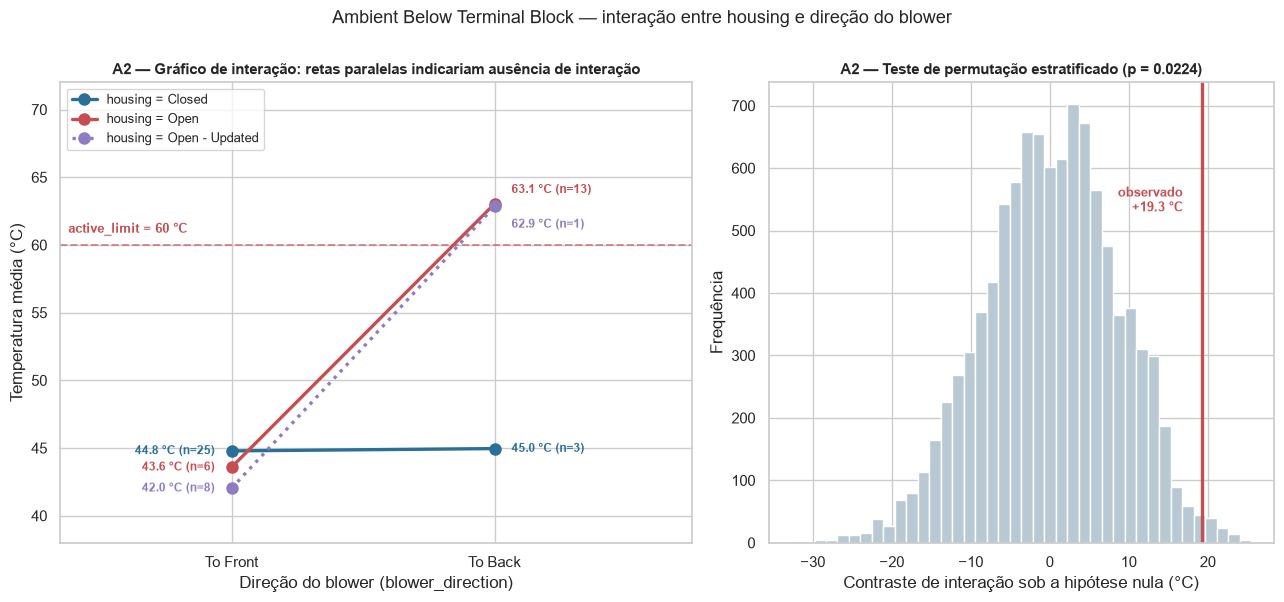

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6), gridspec_kw={'width_ratios': [1.25, 1]})

# Painel esquerdo: grafico de interacao (retas paralelas => sem interacao)
ax = axes[0]
CORES_HOUSING = {'Closed': '#2A6F97', 'Open': '#C44E52', 'Open - Updated': '#8E7CC3'}
# Deslocamentos manuais: as celulas (Open, To Back) e (Open - Updated, To Back)
# ficam a 0,2 C uma da outra e seus rotulos colidiriam se centralizados.
OFFSETS = {
    ('Closed', 'To Front'): (-12, 0, 'right'), ('Closed', 'To Back'): (12, 0, 'left'),
    ('Open', 'To Front'): (-12, 0, 'right'), ('Open', 'To Back'): (12, 10, 'left'),
    ('Open - Updated', 'To Front'): (-12, 0, 'right'),
    ('Open - Updated', 'To Back'): (12, -13, 'left'),
}
for housing_nome in ['Closed', 'Open', 'Open - Updated']:
    grupo = a[a['housing'] == housing_nome]
    resumo = grupo.groupby('blower_direction')['temp'].agg(['mean', 'count']).reindex(ordem)
    estilo = ':' if housing_nome == 'Open - Updated' else '-'
    ax.plot(ordem, resumo['mean'], marker='o', ms=8, lw=2.4, ls=estilo,
            color=CORES_HOUSING[housing_nome], label=f'housing = {housing_nome}')
    for x_pos, direcao in enumerate(ordem):
        mu, n_celula = resumo.loc[direcao, 'mean'], resumo.loc[direcao, 'count']
        if pd.isna(mu):
            continue
        dx, dy, alinhamento = OFFSETS[(housing_nome, direcao)]
        ax.annotate(f'{mu:.1f} °C (n={int(n_celula)})', (x_pos, mu),
                    textcoords='offset points', xytext=(dx, dy), ha=alinhamento,
                    va='center', fontsize=8.5, color=CORES_HOUSING[housing_nome],
                    fontweight='bold')
ax.axhline(LIMITE_A, ls='--', color='#C44E52', lw=1.4, alpha=0.6)
ax.text(-0.62, LIMITE_A + 0.9, f'active_limit = {LIMITE_A:.0f} °C', color='#C44E52',
        ha='left', fontsize=9, fontweight='bold')
ax.set_xlim(-0.65, 1.75)
ax.set_ylim(38, 72)
ax.set_xlabel('Direção do blower (blower_direction)')
ax.set_ylabel('Temperatura média (°C)')
ax.set_title('A2 — Gráfico de interação: retas paralelas indicariam ausência de interação',
             fontsize=10.5, fontweight='bold')
ax.legend(loc='upper left', fontsize=9)

# Painel direito: distribuicao nula do contraste de interacao
ax = axes[1]
ax.hist(distribuicao_nula, bins=40, color='#B8C9D4', edgecolor='white')
ax.axvline(did_observado, color='#C44E52', lw=2.4)
ax.annotate(f'observado\n{did_observado:+.1f} °C', (did_observado, ax.get_ylim()[1] * 0.72),
            xytext=(-14, 0), textcoords='offset points', ha='right',
            fontsize=9.5, color='#C44E52', fontweight='bold')
ax.set_xlabel('Contraste de interação sob a hipótese nula (°C)')
ax.set_ylabel('Frequência')
ax.set_title(f'A2 — Teste de permutação estratificado (p = {p_perm:.4f})',
             fontsize=10.5, fontweight='bold')

fig.suptitle(f'{SENSOR_A} — interação entre housing e direção do blower', fontsize=13, y=1.00)
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/hip_a2_interacao_housing_blower.png', dpi=150, bbox_inches='tight')
plt.show()

### Leitura da A2

**O padrão observado é exatamente o previsto pela hipótese.** As retas do gráfico de interação não são paralelas — elas divergem fortemente:

| `housing` | `To Front` | `To Back` | efeito do `To Back` |
|---|---|---|---|
| `Open` | 43,58 °C (n=6) | **63,05 °C** (n=13) | **+19,47 °C** |
| `Closed` | 44,79 °C (n=25) | 44,96 °C (n=3) | **+0,17 °C** |
| `Open - Updated` | 42,03 °C (n=8) | 62,85 °C (n=1) | +20,82 °C |

Com o housing aberto, mudar a direção do blower vale ~19,5 °C. Com o housing fechado, vale **0,17 °C** — ou seja, nada. O contraste de interação observado (`Open` menos `Closed`) é de **+19,30 °C**, e o teste de permutação estratificado devolve ***p* = 0,0224** — o valor observado fica no percentil 99,1 da distribuição nula, como mostra o painel direito.

Note que a magnitude é significativa a 5%, mas **não a 1%**. Com apenas 47 runs na grade e uma célula de *n* = 3, esse é o limite do que a base atual consegue afirmar: o padrão é forte e coerente, a evidência estatística é moderada.

**Interpretação de engenharia — e o valor prático da hipótese.** O resultado é consistente com o mecanismo proposto: o housing fechado atua como **barreira física**, bloqueando o caminho pelo qual o ar quente empurrado para trás alcançaria o compartimento do terminal block. Se essa leitura se confirmar, a consequência de projeto é direta e barata: **não é necessário reprojetar o sistema de fluxo de ar para proteger o terminal block — basta manter o housing fechado.** A configuração `Closed` entrega ~44,8 °C independentemente da direção do soprador, com margem confortável para o limite de 60 °C. Isso preserva a direção do blower como grau de liberdade livre para otimizar *outros* pontos térmicos do produto.

**Ressalva metodológica — esta é a hipótese mais frágil das quatro.** A célula `Closed` × `To Back` tem apenas **n = 3 runs**. Um efeito simples estimado sobre 3 observações é instável, e o *p* = 0,0224 deve ser lido como indício, não como confirmação: com essa contagem, a estimativa de +0,17 °C tem intervalo de incerteza largo o bastante para acomodar um efeito real de vários graus. Além disso, o desenho experimental é fortemente desbalanceado — `Closed` concentra-se em `To Front` (25 de 28 runs) e `Open` em `To Back` (13 de 19). **A validação adequada exige runs adicionais na célula `Closed` × `To Back`**, e essa é uma recomendação concreta que este notebook entrega para o próximo ciclo de ensaios do parceiro.

---

# Bloco B — `AC Blower Windings`

**Área-chave:** `Main Vent Sys` · **Limite de engenharia:** 175 °C · **56 runs**

Sensor no enrolamento (bobina) do motor do soprador AC. Diferentemente do Bloco A — onde o sensor mede o ar de um compartimento e portanto responde ao projeto térmico do gabinete —, aqui o sensor mede um componente que **gera o próprio calor**: um enrolamento sob carga elétrica dissipa energia por efeito Joule. Essa diferença de natureza física é o que motiva a hipótese B1.

## B1 — O enrolamento do blower opera em patamar saturado, sem alavanca de projeto materialmente relevante

> **Hipótese:** fora do modo Pyro, a temperatura do enrolamento se concentra em um patamar estreito e muito distante do seu limite, e **nenhuma das variáveis de projeto do DoE** (`housing`, `blower_direction`, `deflector_hole`, `material_coil_support`, `board_position`) **a desloca de forma materialmente relevante** — o sensor é governado pelo regime de operação do motor, não pelo projeto térmico do gabinete.

**Justificativa da formulação.** Um enrolamento sob carga tem uma fonte de calor interna — dissipação por efeito Joule — que tipicamente domina sobre a troca com o ar do compartimento. Se essa leitura estiver certa, o sensor deveria se comportar como um **indicador do modo de operação** (quanta corrente o motor está puxando), e não como um indicador da qualidade do projeto térmico. A consequência prática é forte: significaria que este sensor **não deve entrar como variável-alvo de otimização de projeto**, porque nenhuma mudança de gabinete disponível o move o suficiente para importar.

**Por que essa hipótese vale a pena mesmo sendo "negativa".** Uma hipótese que prevê *ausência* de efeito relevante é tão útil quanto uma que prevê presença — ela evita que o projeto gaste esforço de modelagem e de ensaio físico tentando otimizar um alvo que não responde. Combinada ao fato de o sensor ter **zero excedências e 40 °C de margem**, ela sustenta uma recomendação de despriorização baseada em evidência, e não em intuição.

**Atenção à métrica: por que η² sozinho não resolve esta hipótese.** O η² mede variância *relativa* — a fração da variância total que um fator explica. Isso o torna traiçoeiro justamente aqui: ao remover o Pyro, a variância total do sensor colapsa, e qualquer fator que explique uma parte dessa variância residual minúscula exibe um η² alto **sem que o efeito absoluto seja grande**. O código abaixo deixa essa armadilha visível em vez de escondê-la, reportando as duas métricas lado a lado.

O critério correto para a hipótese é o **efeito absoluto em °C, comparado à margem de engenharia disponível** — porque é isso que decide se uma mudança de projeto altera o resultado do ensaio de conformidade.

**Como será testada.** (i) Medidas de dispersão do recorte não-Pyro — CV, IQR e concentração de runs em faixa estreita; (ii) para cada fator, o **efeito absoluto** (maior diferença entre médias de categoria, em °C), descartando categorias com menos de 3 runs, que não sustentam uma média comparável; (iii) esse efeito absoluto expresso como percentual da margem de 40 °C; e (iv) o η² nas duas versões (com e sem Pyro), para documentar a inversão da métrica relativa.

In [9]:
b_nao_pyro = b[b['run_case'] != 'Pyro']
b_pyro = b[b['run_case'] == 'Pyro']

FAIXA_INF, FAIXA_SUP = 100, 110
na_faixa = b_nao_pyro['temp'].between(FAIXA_INF, FAIXA_SUP).sum()

print(f'Recorte NAO-Pyro (n={len(b_nao_pyro)}):')
print(f'  media      : {b_nao_pyro["temp"].mean():.2f} C')
print(f'  desvio     : {b_nao_pyro["temp"].std():.2f} C')
print(f'  CV         : {b_nao_pyro["temp"].std() / b_nao_pyro["temp"].mean() * 100:.2f} %')
print(f'  IQR        : {b_nao_pyro["temp"].quantile(.75) - b_nao_pyro["temp"].quantile(.25):.2f} C')
print(f'  faixa      : {b_nao_pyro["temp"].min():.2f} a {b_nao_pyro["temp"].max():.2f} C')
print(f'  runs entre {FAIXA_INF} e {FAIXA_SUP} C: {na_faixa} de {len(b_nao_pyro)} '
      f'({na_faixa / len(b_nao_pyro) * 100:.0f}%)')
print(f'  margem ate o limite de {LIMITE_B:.0f} C, no pior run de toda a base: '
      f'{LIMITE_B - b["temp"].max():.1f} C')

print(f'\nPara referencia de contraste, o CV do {SENSOR_A} e '
      f'{a["temp"].std() / a["temp"].mean() * 100:.2f} % — cerca de '
      f'{(a["temp"].std() / a["temp"].mean()) / (b_nao_pyro["temp"].std() / b_nao_pyro["temp"].mean()):.1f}x maior.')

Recorte NAO-Pyro (n=48):
  media      : 103.07 C
  desvio     : 4.38 C
  CV         : 4.25 %
  IQR        : 5.94 C
  faixa      : 93.46 a 108.85 C
  runs entre 100 e 110 C: 38 de 48 (79%)
  margem ate o limite de 175 C, no pior run de toda a base: 40.0 C

Para referencia de contraste, o CV do Ambient Below Terminal Block e 24.14 % — cerca de 5.7x maior.


In [10]:
FATORES_PROJETO = ['housing', 'blower_direction', 'deflector_hole',
                   'material_coil_support', 'board_position']
FATORES_OPERACAO = ['run_case', 'losses']
N_MIN = 3  # categorias com menos de 3 runs nao sustentam uma media comparavel

MARGEM = LIMITE_B - b['temp'].max()


def efeito_absoluto(frame, fator, alvo='temp', n_min=N_MIN):
    """Maior diferenca entre as medias das categorias de `fator`, em C.

    Diferente do eta2, nao depende da variancia total do recorte — por isso nao
    infla quando a variancia colapsa. Categorias com menos de `n_min` runs sao
    descartadas para nao deixar uma media de 1 observacao definir a amplitude.
    """
    g = frame.groupby(fator, observed=True)[alvo].agg(['mean', 'count'])
    g = g[g['count'] >= n_min]
    return g['mean'].max() - g['mean'].min() if len(g) >= 2 else np.nan


TODOS_FATORES = FATORES_PROJETO + FATORES_OPERACAO
diagnostico = pd.DataFrame({
    'efeito absoluto nao-Pyro (C)': {f: efeito_absoluto(b_nao_pyro, f) for f in TODOS_FATORES},
    'eta2 (todos os runs)': {f: eta2(b, f) for f in TODOS_FATORES},
    'eta2 (apenas nao-Pyro)': {f: eta2(b_nao_pyro, f) for f in TODOS_FATORES},
}).round(3).sort_values('efeito absoluto nao-Pyro (C)', ascending=False)
diagnostico['% da margem de 40 C'] = (
    diagnostico['efeito absoluto nao-Pyro (C)'] / MARGEM * 100).round(1)

print(f'Margem disponivel ate o active_limit de {LIMITE_B:.0f} C, '
      f'medida a partir do pior run ja registrado: {MARGEM:.1f} C\n')
print(diagnostico.to_string())

print(f'\nPara comparacao, o deslocamento causado pelo MODO DE OPERACAO:')
print(f'  media nao-Pyro : {b_nao_pyro["temp"].mean():.2f} C')
print(f'  media Pyro     : {b_pyro["temp"].mean():.2f} C')
print(f'  deslocamento   : {b_pyro["temp"].mean() - b_nao_pyro["temp"].mean():+.2f} C '
      f'({(b_pyro["temp"].mean() - b_nao_pyro["temp"].mean()) / MARGEM * 100:.0f}% da margem)')
print('  (a hipotese B3, adiante, mostra que este deslocamento esta SUBESTIMADO)')

Margem disponivel ate o active_limit de 175 C, medida a partir do pior run ja registrado: 40.0 C

                       efeito absoluto nao-Pyro (C)  eta2 (todos os runs)  eta2 (apenas nao-Pyro)  % da margem de 40 C
run_case                                      8.696                 0.489                   0.490                 21.7
housing                                       8.409                 0.108                   0.767                 21.0
losses                                        7.847                 0.510                   0.616                 19.6
deflector_hole                                6.559                 0.055                   0.509                 16.4
blower_direction                              6.116                 0.087                   0.428                 15.3
material_coil_support                         3.969                 0.002                   0.130                  9.9
board_position                                3.168                 0

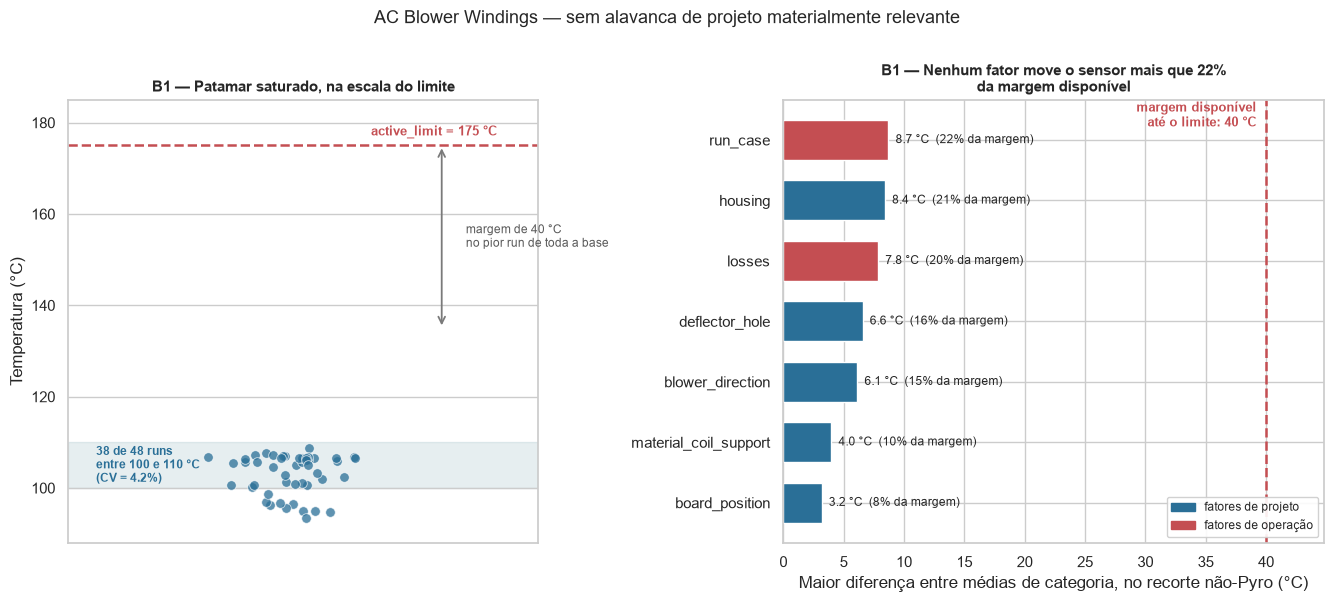

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 6), gridspec_kw={'width_ratios': [1, 1.15]})

# Painel esquerdo: o patamar, na mesma escala do limite de engenharia
ax = axes[0]
ax.axhspan(FAIXA_INF, FAIXA_SUP, color='#3E7C8E', alpha=0.13, zorder=0)
rng_plot = np.random.default_rng(7)
x_jitter = rng_plot.normal(0, 0.055, len(b_nao_pyro))
ax.scatter(x_jitter, b_nao_pyro['temp'], s=48, color='#2A6F97',
           alpha=0.75, edgecolor='white', lw=0.6, zorder=3, label='runs não-Pyro')
ax.axhline(LIMITE_B, ls='--', color='#C44E52', lw=1.8, zorder=2)
ax.text(0.28, LIMITE_B + 2.2, f'active_limit = {LIMITE_B:.0f} °C',
        color='#C44E52', ha='right', fontsize=9.5, fontweight='bold')
ax.annotate('', xy=(0.20, b['temp'].max()), xytext=(0.20, LIMITE_B),
            arrowprops=dict(arrowstyle='<->', color='#7A7A7A', lw=1.3))
ax.text(0.235, (LIMITE_B + b['temp'].max()) / 2,
        f'margem de {MARGEM:.0f} °C\nno pior run de toda a base',
        fontsize=8.8, color='#5A5A5A', va='center')
ax.text(-0.30, (FAIXA_INF + FAIXA_SUP) / 2,
        f'{na_faixa} de {len(b_nao_pyro)} runs\nentre {FAIXA_INF} e {FAIXA_SUP} °C\n(CV = '
        f'{b_nao_pyro["temp"].std() / b_nao_pyro["temp"].mean() * 100:.1f}%)',
        fontsize=8.8, color='#2A6F97', va='center', fontweight='bold')
ax.set_xlim(-0.34, 0.34)
ax.set_ylim(88, 185)
ax.set_xticks([])
ax.set_ylabel('Temperatura (°C)')
ax.set_title('B1 — Patamar saturado, na escala do limite', fontsize=10.5, fontweight='bold')

# Painel direito: efeito ABSOLUTO de cada fator, contra a margem de engenharia
ax = axes[1]
plot_ef = diagnostico['efeito absoluto nao-Pyro (C)'].dropna().sort_values()
cores_ef = ['#C44E52' if f in FATORES_OPERACAO else '#2A6F97' for f in plot_ef.index]
barras = ax.barh(plot_ef.index, plot_ef.values, color=cores_ef, height=0.66)
for barra, valor in zip(barras, plot_ef.values):
    ax.text(valor + 0.6, barra.get_y() + barra.get_height() / 2,
            f'{valor:.1f} °C  ({valor / MARGEM * 100:.0f}% da margem)', va='center', fontsize=8.8)
ax.axvline(MARGEM, ls='--', color='#C44E52', lw=1.8)
ax.text(MARGEM - 0.8, len(plot_ef) - 0.35,
        f'margem disponível\naté o limite: {MARGEM:.0f} °C',
        ha='right', va='top', fontsize=9, color='#C44E52', fontweight='bold')
ax.set_xlim(0, MARGEM * 1.12)
ax.set_xlabel('Maior diferença entre médias de categoria, no recorte não-Pyro (°C)')
ax.set_title('B1 — Nenhum fator move o sensor mais que 22%\nda margem disponível',
             fontsize=10.5, fontweight='bold')
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color='#2A6F97'),
                   plt.Rectangle((0, 0), 1, 1, color='#C44E52')],
          labels=['fatores de projeto', 'fatores de operação'],
          loc='lower right', fontsize=8.5, framealpha=0.9)

fig.suptitle(f'{SENSOR_B} — sem alavanca de projeto materialmente relevante',
             fontsize=13, y=1.00)
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/hip_b1_patamar_saturado.png', dpi=150, bbox_inches='tight')
plt.show()

### Leitura da B1

**O patamar existe e é estreito.** Fora do Pyro, os 48 runs restantes se concentram numa faixa notavelmente apertada: **CV de 4,25%**, IQR de apenas 5,9 °C, e **38 dos 48 runs (79%) caem entre 100 e 110 °C**. Para dimensionar: o CV do `Ambient Below Terminal Block` é 24,1% — cerca de **5,7× maior**. Um sensor varia; o outro, essencialmente, não. O painel esquerdo mostra o patamar na escala do próprio limite de engenharia, e é essa proporção que importa: a nuvem inteira de runs fica comprimida na parte de baixo do gráfico, a 66–82 °C do limite.

**A hipótese é sustentada — mas só pela métrica certa, e vale explicar por quê.**

Nenhum fator move o sensor de forma material. O maior efeito absoluto entre todos é `housing`, com **8,4 °C** — o que representa **21% da margem de 40 °C**. `material_coil_support`, variável central de uma das hipóteses de negócio do projeto segundo a Seção 4.2.1, move **4,0 °C (10% da margem)**. Nenhuma dessas mudanças chega perto de alterar o resultado de um ensaio de conformidade num sensor que nunca excedeu seu limite.

**A armadilha do η², documentada em vez de escondida.** Se a análise tivesse parado no η², a conclusão poderia se inverter conforme o recorte escolhido:

| fator | efeito absoluto (não-Pyro) | η² (todos os runs) | η² (só não-Pyro) |
|---|---|---|---|
| `housing` | 8,4 °C | 0,108 | **0,767** |
| `deflector_hole` | 6,6 °C | 0,055 | **0,509** |
| `blower_direction` | 6,1 °C | 0,087 | **0,428** |
| `material_coil_support` | 4,0 °C | 0,002 | 0,130 |

Olhando só a coluna do meio, os fatores de projeto "explicam quase nada". Olhando só a da direita, `housing` "explica 77% da variância" — e alguém poderia concluir o oposto da hipótese. **As duas leituras estão numericamente corretas e ambas são enganosas isoladamente.** A razão é que η² é, literalmente, uma razão: ao remover o Pyro, a soma de quadrados total do sensor cai de **4.499 para 902** — um denominador 5× menor. Explicar uma fração grande de uma variância minúscula não significa efeito grande. O efeito absoluto de `housing` continua sendo os mesmos 8,4 °C nos dois recortes; o que muda é só contra o que ele está sendo comparado.

Por isso o critério adotado é o **efeito absoluto contra a margem de engenharia**: é a única métrica que responde à pergunta que a engenharia realmente faz — *essa mudança de projeto altera o resultado do ensaio?* Aqui, a resposta é não para todos os fatores.

**Conclusão para o projeto.** `AC Blower Windings` se comporta como um **indicador de modo de operação**, não como um indicador de qualidade do projeto térmico: entrar em Pyro desloca o sensor em **+16,0 °C** (40% da margem) — quase o dobro do maior fator de projeto, e **quase o triplo** uma vez corrigido o erro de rótulo tratado na B3. Somando isso às **zero excedências** e aos **40 °C de margem** no pior run já registrado, a recomendação é despriorizá-lo como variável-alvo de otimização — nenhuma decisão de gabinete disponível no DoE o move o suficiente para importar, e ele não está em risco. O esforço de modelagem e de ensaio físico rende muito mais aplicado a pontos como o do Bloco A.

**Ressalvas.**
1. **A hipótese afirma ausência de efeito *material*, não ausência de efeito.** `housing` tem, sim, um efeito real de ~8 °C sobre este sensor. A afirmação é que 8 °C não são relevantes num componente com 40 °C de margem — o que é um juízo de engenharia, não um resultado estatístico, e deve ser validado com o parceiro.
2. `losses` tem 14 categorias contra 2–7 dos demais fatores. O η² é enviesado para cima pelo número de categorias, então seu 0,510 não é diretamente comparável aos outros — na prática `losses` e `run_case` são descritores quase redundantes do mesmo regime de ensaio.
3. A afirmação é **condicional ao espaço de projeto explorado neste DoE** — insensível *às faixas testadas destas variáveis*, não imune a qualquer alteração concebível de projeto.
4. O deslocamento de +16,0 °C atribuído ao Pyro está **subestimado**, pelo motivo tratado na hipótese seguinte.

## B3 — Há erro de rotulagem em `run_case` nas Runs 62 e 63 (qualidade de dados)

> **Hipótese:** as Runs 62 e 63 estão rotuladas como `run_case = Pyro`, mas correspondem de fato a um regime Broil — o que contamina qualquer agregação ou modelo que use `run_case` como preditor.

**Justificativa da formulação.** A hipótese não nasceu de uma suspeita genérica de "dados sujos": ela nasceu de uma **anomalia observada**. Ao inspecionar o recorte Pyro do `AC Blower Windings`, a distribuição aparece claramente bimodal — seis runs entre 118 e 135 °C e dois runs isolados abaixo de 96 °C. Como `run_case` é o fator de maior η² neste sensor (B1), um erro de rótulo nele propaga para toda a análise.

**Por que ela pertence ao artefato.** É a hipótese mais barata de testar e a de maior efeito colateral: se confirmada, **todo agrupamento por `run_case` no projeto precisa ser revisto**, incluindo os gráficos da Seção 4.2.1 e qualquer modelo que use essa coluna como preditor. Vale notar que ela conecta diretamente com o item **R07** da Seção 4.1 da documentação ("identificação de simulações históricas inconsistentes"), que é um dos requisitos declarados do projeto — este é exatamente o tipo de achado que o R07 pede.

**Como será testada.** Três vias independentes de evidência: (i) separação entre grupos — verificar se os dois runs caem dentro da faixa Pyro ou da faixa Broil; (ii) evidência documental — a coluna `reason`, preenchida pela equipe de ensaio, contradiz o `run_case`; (iii) corroboração cruzada — se o problema é do *rótulo do run*, o mesmo padrão deve aparecer no outro sensor. **Este é o único ponto do notebook em que os dois sensores são usados juntos, e é justificado: a hipótese é sobre o run, não sobre o sensor.**

In [12]:
SUSPEITAS = ['Run 62', 'Run 63']

print('=== EVIDENCIA (i): separacao entre as faixas Pyro e nao-Pyro ===\n')
for nome, rec in [(SENSOR_B, b), (SENSOR_A, a)]:
    pyro = rec[rec['run_case'] == 'Pyro']
    legitimos = pyro[~pyro['run_id'].isin(SUSPEITAS)]
    suspeitos = pyro[pyro['run_id'].isin(SUSPEITAS)]
    nao_pyro = rec[rec['run_case'] != 'Pyro']
    print(f'{nome}')
    print(f'  faixa dos demais Pyro (n={len(legitimos)}) : '
          f'{legitimos["temp"].min():.2f} a {legitimos["temp"].max():.2f} C')
    print(f'  faixa dos runs nao-Pyro (n={len(nao_pyro)}): '
          f'{nao_pyro["temp"].min():.2f} a {nao_pyro["temp"].max():.2f} C')
    print(f'  Runs 62 e 63                       : {sorted(suspeitos["temp"].round(2).tolist())} C')
    print(f'  -> ficam ao menos '
          f'{legitimos["temp"].min() - suspeitos["temp"].max():.2f} C ABAIXO do Pyro mais frio')
    # A faixa nao-Pyro do Ambient Below Terminal Block cobre quase todo o eixo, entao
    # "cair dentro dela" nao diz nada nesse sensor. A posicao no ranking, sim.
    ordenado = rec.sort_values('temp').reset_index(drop=True)
    posicoes = [int(ordenado.index[ordenado['run_id'] == r][0]) + 1 for r in SUSPEITAS]
    print(f'  -> posicao no ranking das {len(rec)} leituras (1 = mais fria): '
          f'{dict(zip(SUSPEITAS, posicoes))}\n')

=== EVIDENCIA (i): separacao entre as faixas Pyro e nao-Pyro ===

AC Blower Windings
  faixa dos demais Pyro (n=6) : 118.21 a 135.00 C
  faixa dos runs nao-Pyro (n=48): 93.46 a 108.85 C
  Runs 62 e 63                       : [92.84, 95.9] C
  -> ficam ao menos 22.31 C ABAIXO do Pyro mais frio
  -> posicao no ranking das 56 leituras (1 = mais fria): {'Run 62': 1, 'Run 63': 7}

Ambient Below Terminal Block
  faixa dos demais Pyro (n=6) : 48.94 a 58.49 C
  faixa dos runs nao-Pyro (n=48): 39.56 a 80.53 C
  Runs 62 e 63                       : [37.31, 38.57] C
  -> ficam ao menos 10.37 C ABAIXO do Pyro mais frio
  -> posicao no ranking das 56 leituras (1 = mais fria): {'Run 62': 1, 'Run 63': 2}



In [13]:
print('=== EVIDENCIA (ii): a coluna `reason` contradiz o `run_case` ===\n')
doc = b[b['run_case'] == 'Pyro'][['run_id', 'run_case', 'reason', 'temp']].sort_values('temp', ascending=False)
print(doc.to_string(index=False))
print('\nOs dois runs cujo `reason` diz "Broil" sao exatamente os dois fora do padrao Pyro.')

print('\n\n=== EVIDENCIA (iii): efeito do erro sobre a agregacao por run_case ===\n')
impacto = []
for nome, rec in [(SENSOR_B, b), (SENSOR_A, a)]:
    pyro = rec[rec['run_case'] == 'Pyro']
    legitimos = pyro[~pyro['run_id'].isin(SUSPEITAS)]
    impacto.append({
        'sensor': nome,
        'media Pyro como rotulado (C)': round(pyro['temp'].mean(), 2),
        'media Pyro sem 62/63 (C)': round(legitimos['temp'].mean(), 2),
        'vies (C)': round(pyro['temp'].mean() - legitimos['temp'].mean(), 2),
        'eta2 de run_case como rotulado': round(eta2(rec, 'run_case'), 3),
        'eta2 de run_case sem 62/63': round(eta2(rec[~rec['run_id'].isin(SUSPEITAS)], 'run_case'), 3),
    })
print(pd.DataFrame(impacto).set_index('sensor').T.to_string())

=== EVIDENCIA (ii): a coluna `reason` contradiz o `run_case` ===

                  run_id run_case                                           reason   temp
                  Run 61     Pyro              Aluminium Plate Pyro Blower On High 135.00
                  Run 60     Pyro            Aluminium Plate Pyro Blower On Medium 133.21
                  Run 57     Pyro                   Aluminium Plate Pyro Blower On 128.79
    Run 2 - Pyro Flipped     Pyro                                              NaN 126.70
                   Run 1     Pyro                                              NaN 121.94
Run 3 - Pyro Fans in Low     Pyro                            Fan velocity 1500 RPM 118.21
                  Run 63     Pyro Aluminium Plate Broil wo Cookitop and fan on low  95.90
                  Run 62     Pyro                Aluminium Plate Broil wo Cookitop  92.84

Os dois runs cujo `reason` diz "Broil" sao exatamente os dois fora do padrao Pyro.


=== EVIDENCIA (iii): efeito do erro so

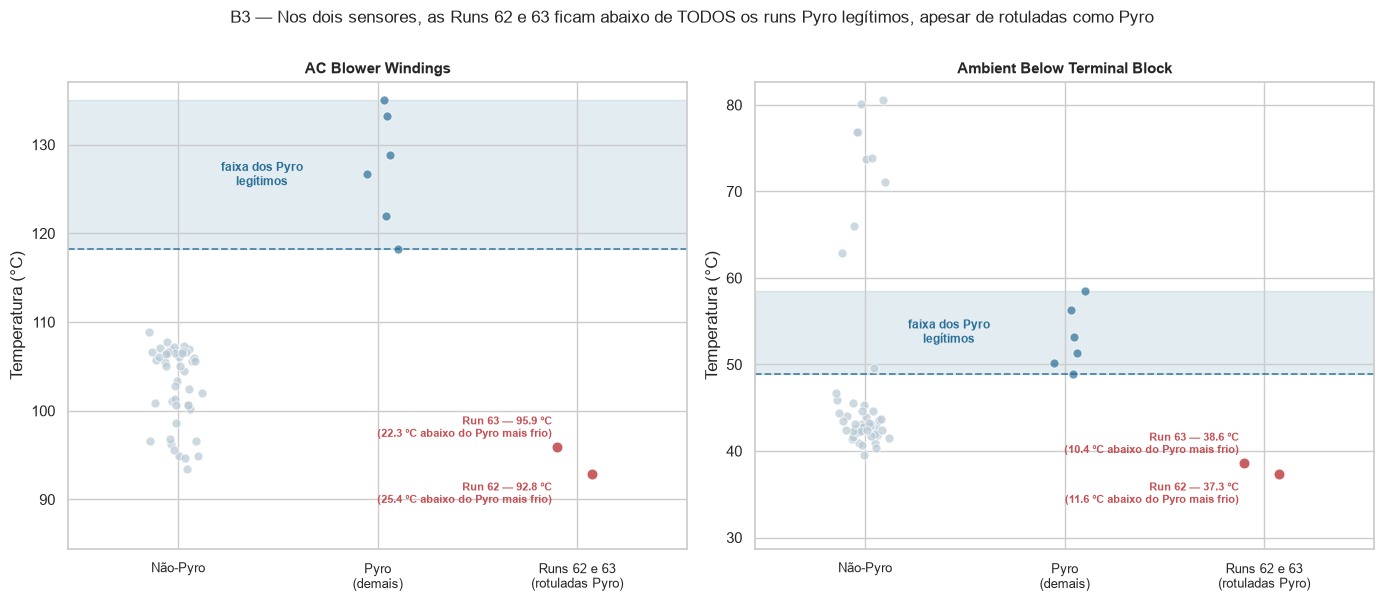

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, (nome, rec, limite) in zip(axes, [(SENSOR_B, b, LIMITE_B), (SENSOR_A, a, LIMITE_A)]):
    rec = rec.copy()
    rec['grupo'] = np.where(rec['run_id'].isin(SUSPEITAS), 'Runs 62 e 63 (suspeitas)',
                            np.where(rec['run_case'] == 'Pyro', 'Pyro (demais)', 'Não-Pyro'))
    ordem_g = ['Não-Pyro', 'Pyro (demais)', 'Runs 62 e 63 (suspeitas)']
    cores_g = {'Não-Pyro': '#B8C9D4', 'Pyro (demais)': '#2A6F97',
               'Runs 62 e 63 (suspeitas)': '#C44E52'}
    rng_plot = np.random.default_rng(11)
    for i, g in enumerate(ordem_g):
        vals = rec.loc[rec['grupo'] == g, 'temp']
        ax.scatter(rng_plot.normal(i, 0.075, len(vals)), vals, s=62 if 'suspeitas' in g else 42,
                   color=cores_g[g], alpha=0.9 if 'suspeitas' in g else 0.7,
                   edgecolor='white', lw=0.7, zorder=4 if 'suspeitas' in g else 3)

    # Sombreia apenas a faixa dos Pyro legitimos. A faixa nao-Pyro nao e sombreada
    # de proposito: no Ambient Below Terminal Block ela cobre quase todo o eixo, e
    # destaca-la sugeriria uma separacao entre os grupos que so existe no outro sensor.
    legitimos = rec[(rec['run_case'] == 'Pyro') & (~rec['run_id'].isin(SUSPEITAS))]['temp']
    ax.axhspan(legitimos.min(), legitimos.max(), color='#2A6F97', alpha=0.13, zorder=0)
    ax.text(0.42, (legitimos.min() + legitimos.max()) / 2,
            'faixa dos Pyro\nlegítimos', fontsize=8.5, color='#2A6F97',
            va='center', ha='center', fontweight='bold')
    ax.axhline(legitimos.min(), ls='--', color='#2A6F97', lw=1.3, alpha=0.8, zorder=1)

    suspeitos = rec[rec['run_id'].isin(SUSPEITAS)].sort_values('temp')
    # A mais fria recebe rotulo abaixo e a mais quente acima: no Ambient Below
    # Terminal Block as duas distam ~1,3 C e colidiriam se centralizadas.
    for pos, (_, linha) in enumerate(suspeitos.iterrows()):
        dy = -14 if pos == 0 else 14
        ax.annotate(f'{linha["run_id"]} — {linha["temp"]:.1f} °C\n'
                    f'({legitimos.min() - linha["temp"]:.1f} °C abaixo do Pyro mais frio)',
                    (2, linha['temp']), xytext=(-18, dy), textcoords='offset points',
                    ha='right', va='center', fontsize=8.2, color='#C44E52', fontweight='bold')

    ax.set_xticks(range(3))
    ax.set_xticklabels(['Não-Pyro', 'Pyro\n(demais)', 'Runs 62 e 63\n(rotuladas Pyro)'], fontsize=9)
    ax.set_xlim(-0.55, 2.55)
    # Folga extra embaixo para caber o rotulo da run mais fria, que fica abaixo do ponto.
    baixo, alto = rec['temp'].min(), rec['temp'].max()
    ax.set_ylim(baixo - (alto - baixo) * 0.20, alto + (alto - baixo) * 0.05)
    ax.set_ylabel('Temperatura (°C)')
    ax.set_title(nome, fontsize=10.5, fontweight='bold')

fig.suptitle('B3 — Nos dois sensores, as Runs 62 e 63 ficam abaixo de TODOS os runs '
             'Pyro legítimos, apesar de rotuladas como Pyro', fontsize=12.5, y=1.00)
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/hip_b3_runs_mal_rotulados.png', dpi=150, bbox_inches='tight')
plt.show()

### Leitura da B3

**As três vias de evidência convergem.**

**(i) Separação entre grupos.** No `AC Blower Windings`, os seis runs Pyro restantes ocupam a faixa de 118,2 a 135,0 °C, e os runs não-Pyro ocupam 93,5 a 108,9 °C — **os dois grupos não se sobrepõem**, e há um vão de quase 10 °C entre eles. As Runs 62 e 63 marcam 92,8 e 95,9 °C: caem dentro da faixa não-Pyro e ficam **ao menos 22,3 °C abaixo** do run Pyro mais frio (25,4 °C no caso da Run 62). Não é um caso de estarem "um pouco baixas" — elas estão do lado errado de uma fronteira limpa.

**(ii) Evidência documental.** A coluna `reason`, preenchida pela própria equipe de ensaio, contradiz o `run_case` nesses dois registros e apenas neles:

| `run_id` | `run_case` | `reason` | temp (°C) |
|---|---|---|---|
| Run 61 | Pyro | Aluminium Plate **Pyro** Blower On High | 135,00 |
| Run 60 | Pyro | Aluminium Plate **Pyro** Blower On Medium | 133,21 |
| Run 57 | Pyro | Aluminium Plate **Pyro** Blower On | 128,79 |
| **Run 63** | **Pyro** | Aluminium Plate **Broil** wo Cookitop and fan on low | **95,90** |
| **Run 62** | **Pyro** | Aluminium Plate **Broil** wo Cookitop | **92,84** |

Os dois únicos runs cujo `reason` diz "Broil" são exatamente os dois que destoam termicamente. As duas evidências são independentes — uma vem do texto livre da equipe, outra da medição física — e apontam para o mesmo lugar.

**(iii) Corroboração cruzada entre sensores.** No `Ambient Below Terminal Block`, as Runs 62 e 63 são as **duas leituras mais baixas de todos os 56 runs** (37,31 °C e 38,57 °C), ao menos 10,4 °C abaixo do Pyro mais frio. O padrão se repete em um sensor de outra área-chave, medindo outro fenômeno físico — o que descarta falha de instrumentação em um termopar específico e localiza o problema no **rótulo do run**, exatamente como a hipótese previa.

Vale registrar uma diferença entre os dois sensores, visível no gráfico: no `AC Blower Windings` as faixas Pyro e não-Pyro são disjuntas, então "estar na faixa errada" é um argumento forte por si só. No `Ambient Below Terminal Block` a faixa Pyro (48,9–58,5 °C) está *contida* na faixa não-Pyro (39,6–80,5 °C), e nesse sensor o argumento válido não é o de faixa, mas o de **ranking**: as duas runs são a 1ª e a 2ª mais frias de toda a coluna. Por isso o gráfico sombreia apenas a faixa dos Pyro legítimos — sombrear a faixa não-Pyro sugeriria, no painel da direita, uma separação que não existe.

**Impacto quantificado.** Manter o rótulo como está enviesa a média do modo Pyro em **−8,2 °C** no `AC Blower Windings` e em **−3,8 °C** no `Ambient Below Terminal Block`. Pyro é justamente o modo mais crítico do produto, então o viés atua na direção mais perigosa: **subestimar o pior caso térmico**. O η² de `run_case` no `AC Blower Windings` salta de **0,489 para 0,843** ao remover os dois runs — ou seja, o erro de rótulo estava mascarando o quanto o modo de operação de fato explica esse sensor, e a ressalva 4 da B1 se confirma: o deslocamento real do Pyro não é +16,0 °C, mas **+24,2 °C** (127,31 contra 103,07), o equivalente a 61% da margem de engenharia.

**Encaminhamento.** Diferentemente das outras três, esta hipótese não se resolve com mais dados: resolve-se com **uma confirmação do parceiro**. A recomendação é levar os dois registros à equipe de CFD para verificação e, uma vez confirmados, corrigir o rótulo em [`02_pre_processamento.ipynb`](02_pre_processamento.ipynb) — em vez de descartar os runs, que são dados válidos apenas mal classificados. Enquanto a confirmação não vem, qualquer agregação por `run_case` deve reportar o resultado com e sem as Runs 62 e 63.

---

## Síntese

| # | Sensor | Hipótese | Evidência principal | Status |
|---|---|---|---|---|
| **A1** | `Ambient Below Terminal Block` | `To Back` eleva a temperatura do terminal block | +15,8 °C; *d* = 1,70; Welch *p* = 5,7×10⁻⁴; excedência 47,1% vs. 2,6% (Fisher *p* = 1,3×10⁻⁴) | **Sustentada** |
| **A2** | `Ambient Below Terminal Block` | O efeito de A1 depende do housing estar aberto | +19,5 °C com `Open` vs. +0,2 °C com `Closed`; permutação *p* = 0,0224 | **Indício** — célula crítica com *n* = 3 |
| **B1** | `AC Blower Windings` | Patamar saturado, sem alavanca de projeto relevante | CV 4,25%; 79% dos runs em 10 °C; maior efeito de projeto = 8,4 °C sobre 40 °C de margem | **Sustentada** |
| **B3** | `AC Blower Windings` | Runs 62 e 63 com `run_case` errado | ≥22,3 °C abaixo de todo Pyro legítimo; `reason` diz "Broil"; padrão se repete no outro sensor | **Sustentada** — pendente de confirmação do parceiro |

### O que cada bloco entrega ao projeto

**Bloco A — onde concentrar o esforço.** O terminal block é um ponto de risco real (16,1% de excedência) e, ao mesmo tempo, **controlável**: as configurações que estouram o limite são identificáveis a partir de duas variáveis de projeto já registradas na base. A A2, se validada, aponta uma contramedida barata — manter o housing fechado — que preserva a direção do blower como grau de liberdade para otimizar outros pontos. É o candidato natural a variável-alvo do modelo preditivo.

**Bloco B — onde economizar esforço.** O enrolamento do blower não está em risco (zero excedências, 40 °C de margem) e nenhuma variável de projeto disponível o desloca mais que 21% dessa margem. Modelá-lo como alvo de otimização gastaria capacidade preditiva num ponto que nenhuma decisão de gabinete move de forma relevante. Já a B3 é um achado de qualidade de dados que atende diretamente ao requisito **R07** da Seção 4.1 e cuja correção beneficia todas as análises do projeto que usam `run_case`.

**Nota metodológica que atravessa os dois blocos.** A B1 expõe um risco que vale carregar para as seções seguintes: **métricas relativas de variância (η², R²) mudam de sinal conforme o recorte dos dados**, porque dependem de um denominador que se move. Ao avaliar o modelo preditivo na Seção 4.2.5, o mesmo cuidado se aplica — um R² alto num recorte de variância comprimida não indica um modelo útil, e o erro deve ser sempre reportado em °C absolutos e comparado à margem de engenharia do sensor, que é o critério que o parceiro de fato usa.

### Ressalva geral — confundimento no desenho experimental

As variáveis de projeto do Bloco A **não são independentes entre si** na base:

- `housing = Open` coincide com `blower_direction = To Back` em **13 dos 19 runs**;
- `housing = Open` coincide com `deflector_hole = Open` em **15 dos 19 runs**;
- `blower_direction = To Back` coincide com `deflector_hole = Open` em **15 dos 17 runs**.

Isso significa que **nenhuma das hipóteses do Bloco A isola causalidade**. Elas identificam *configurações de risco* — combinações que, empiricamente, estouram o limite — e não *causas raízes* isoladas. Os mecanismos físicos propostos (condução do ar quente para trás; housing como barreira) são interpretações plausíveis e coerentes com a engenharia do produto, mas a separação estatística entre os três fatores exigiria um DoE fatorial balanceado que a base atual não oferece.

Declarar essa limitação não enfraquece o artefato — ela **delimita corretamente o que o modelo preditivo poderá afirmar**. Um modelo treinado sobre esta base prediz temperatura a partir da configuração, o que atende ao objetivo do projeto (antecipar resultado térmico antes do protótipo); mas não sustenta afirmações contrafactuais do tipo "se mudarmos apenas o housing, a temperatura cai X". Essa distinção deve ser explicitada na Seção 4.2.5, ao verificar a aceitação ou refutação das hipóteses.

### Figuras geradas

Salvas em [`assets/graficos/`](../assets/graficos/) para uso na Seção 4.2.3 de [`documentacao.md`](../documents/documentacao.md):

- `hip_a1_blower_direction.png` — A1
- `hip_a2_interacao_housing_blower.png` — A2
- `hip_b1_patamar_saturado.png` — B1
- `hip_b3_runs_mal_rotulados.png` — B3